# 82 · Regression vs diffusion vs flow, closed loop: who gets around the obstacle?

In [1]:
import time, numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt
from vlacourse.toy_envs import AroundObstacleEnv, collect_around

torch.manual_seed(0)
H, EXEC, T_DIFF = 8, 4, 50
beta = torch.linspace(1e-4, 0.1, T_DIFF); alpha = 1 - beta; abar = torch.cumprod(alpha, 0)

def chunks(eps):
    X, Y = [], []
    for e in eps:
        T = len(e["act"])
        for t in range(T):
            X.append(e["obs"][t]); Y.append(e["act"][np.minimum(np.arange(t, t + H), T - 1)].reshape(-1))
    return torch.tensor(np.array(X)), torch.tensor(np.array(Y))

class Net(nn.Module):
    def __init__(self, extra, h=256):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(4 + extra, h), nn.SiLU(), nn.Linear(h, h), nn.SiLU(), nn.Linear(h, h), nn.SiLU(), nn.Linear(h, 2 * H))
    def forward(self, *xs):
        return self.net(torch.cat(xs, -1))

def train(kind, X, Y, steps=6000):
    torch.manual_seed(0)
    net = Net(0 if kind == "regression" else 2 * H + 1); opt = torch.optim.Adam(net.parameters(), 1e-3)
    for _ in range(steps):
        idx = torch.randint(0, len(X), (256,)); o, a = X[idx], Y[idx]
        if kind == "regression":
            loss = ((net(o) - a) ** 2).mean()
        elif kind == "diffusion":
            t = torch.randint(0, T_DIFF, (256,)); eps = torch.randn_like(a)
            at = abar[t, None].sqrt() * a + (1 - abar[t, None]).sqrt() * eps
            loss = ((net(o, at, t[:, None] / T_DIFF) - eps) ** 2).mean()
        else:
            noise = torch.randn_like(a); tau = torch.rand(256, 1)
            loss = ((net(o, (1 - tau) * noise + tau * a, tau) - (a - noise)) ** 2).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    return net

@torch.no_grad()
def predict(kind, net, o, nfe=10):
    o = torch.tensor(o)[None]
    if kind == "regression":
        return net(o)[0].view(H, 2).numpy()
    x = torch.randn(1, 2 * H)
    if kind == "diffusion":
        ts = torch.linspace(T_DIFF - 1, 0, nfe).long()
        for i, t in enumerate(ts):
            eps = net(o, x, torch.full((1, 1), float(t) / T_DIFF))
            x0 = (x - (1 - abar[t]).sqrt() * eps) / abar[t].sqrt()
            ab_prev = abar[ts[i + 1]] if i + 1 < len(ts) else torch.tensor(1.0)
            x = ab_prev.sqrt() * x0 + (1 - ab_prev).sqrt() * eps
    else:
        for k in range(nfe):
            x = x + net(o, x, torch.full((1, 1), k / nfe)) / nfe
    return x[0].view(H, 2).numpy()

def evaluate(kind, net, n=40, nfe=10):
    env, res, paths = AroundObstacleEnv(), [], []
    for s in range(n):
        o = env.reset(seed=2000 + s); done, q, path = False, [], [env.pos()]
        while not done:
            if not q:
                q = list(predict(kind, net, o, nfe)[:EXEC])
            o, _, done, info = env.step(q.pop(0)); path.append(env.pos())
        res.append(info); paths.append(np.array(path))
    return np.mean([r["success"] for r in res]), np.mean([r["collided"] for r in res]), paths

In [2]:
X, Y = chunks(collect_around(200, seed=0))
nets, scores = {}, {}
for kind in ["regression", "diffusion", "flow"]:
    t0 = time.time(); nets[kind] = train(kind, X, Y)
    scores[kind] = evaluate(kind, nets[kind])
    print(f"{kind:10s} success {scores[kind][0]:.2f}  collided {scores[kind][1]:.2f}  (train {time.time() - t0:.0f}s, 10 NFE for generative heads)")

regression success 0.00  collided 1.00  (train 74s, 10 NFE for generative heads)


diffusion  success 0.78  collided 0.23  (train 51s, 10 NFE for generative heads)


flow       success 0.80  collided 0.20  (train 55s, 10 NFE for generative heads)


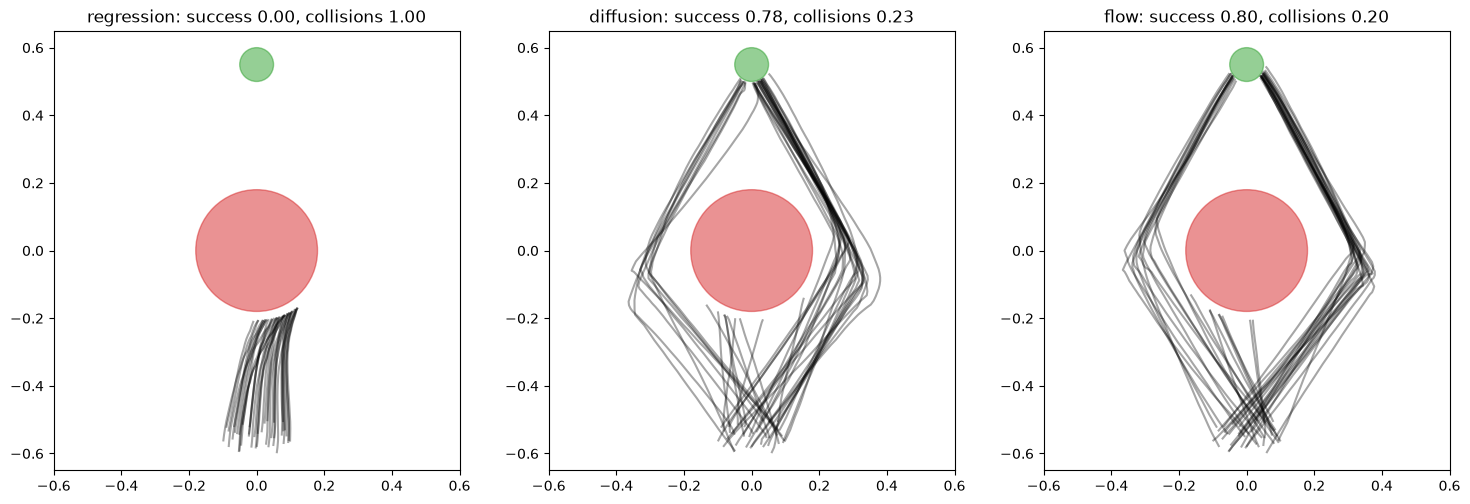

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, kind in zip(axes, scores):
    ax.add_patch(plt.Circle((0, 0), 0.18, color="tab:red", alpha=0.5)); ax.add_patch(plt.Circle((0, 0.55), 0.05, color="tab:green", alpha=0.5))
    for p in scores[kind][2]:
        ax.plot(p[:, 0], p[:, 1], "k", alpha=0.35)
    ax.set_aspect("equal"); ax.set_xlim(-0.6, 0.6); ax.set_ylim(-0.65, 0.65)
    ax.set_title(f"{kind}: success {scores[kind][0]:.2f}, collisions {scores[kind][1]:.2f}")
plt.tight_layout(); plt.show()

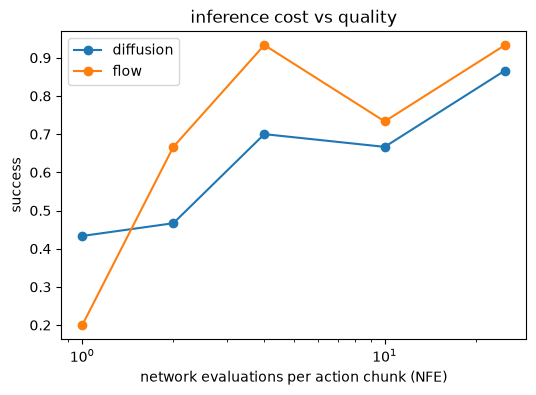

In [4]:
nfes = [1, 2, 4, 10, 25]
plt.figure(figsize=(6, 4))
for kind in ["diffusion", "flow"]:
    plt.plot(nfes, [evaluate(kind, nets[kind], n=30, nfe=k)[0] for k in nfes], "o-", label=kind)
plt.xscale("log"); plt.xlabel("network evaluations per action chunk (NFE)"); plt.ylabel("success"); plt.legend(); plt.title("inference cost vs quality"); plt.show()